# 90 Usage stabilization in detail

Notebook 45 found the **stabilization length**: how many days of data it takes to pin down a customer's usage pattern
(about 4 weeks). That number, and the mid-year change detection built on it, are all the models need. This notebook
holds the rest of that analysis. It isn't used by the models, segments or battery simulation, but it explains how
customers differ and where change detection is hardest:

1. **Differences between customers**: how reliably each customer's pattern can be measured, and how much it drifts.
2. **When in the year patterns are least stable**.
3. **Usage level, and a cross-check with a weather model**: which way of removing weather and season leaves the least
   noise.

It also adds the last column, `level_shift_sd`, to `customer_stability`.

Run after notebook 45. It holds a 1.2 GB array in memory.

## Setup

In [1]:
import math
import warnings

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

warnings.filterwarnings('ignore', message='Mean of empty slice')
warnings.filterwarnings('ignore', message='Degrees of freedom')
warnings.filterwarnings('ignore', category=RuntimeWarning, message='invalid value encountered')

DB_PATH = 'onedrive-export/Data/avangrid.db'
PLOT_DIR = 'onedrive-export/Data/eda'
N_PEER_GROUPS = 16

con = duckdb.connect(DB_PATH)
con.execute('SET enable_progress_bar = false')

## Peer-relative residuals

The same customers × days × hours array of peer-relative residuals as in notebook 45 (imputed hours set to missing),
the stabilization length saved there, and the same correlation helper.

In [2]:
con.execute('''
    CREATE OR REPLACE TEMP TABLE normalized AS
    SELECT a.CUSTOMER_NUMBER, g.peer_group, a.usage_date, a.hour_ending, a.is_imputed,
           a.hourly_kwh / g.mean_kwh_real AS n
    FROM ami_analysis a JOIN customer_peer_groups g USING (CUSTOMER_NUMBER)
''')

customers = con.sql('SELECT CUSTOMER_NUMBER, peer_group FROM customer_peer_groups ORDER BY 1').pl()
slots = con.sql('SELECT DISTINCT usage_date, hour_ending FROM normalized ORDER BY 1, 2').pl()
start_date = slots['usage_date'].min()
slot_day = (slots['usage_date'] - start_date).dt.total_days().to_numpy()
slot_hour = slots['hour_ending'].to_numpy() - 1
N_DAYS = int(slot_day.max()) + 1
dates = pl.date_range(start_date, slots['usage_date'].max(), eager=True)

residual_values = con.sql('''
    SELECT CASE WHEN n.is_imputed THEN NULL ELSE n.n - p.peer_n END::FLOAT AS e
    FROM normalized n JOIN peer_index p USING (peer_group, usage_date, hour_ending)
    ORDER BY n.CUSTOMER_NUMBER, n.usage_date, n.hour_ending
''').pl()['e'].to_numpy()

N_CUST = customers.height
assert residual_values.size == N_CUST * slots.height, 'every customer should have one row per slot'

E = np.full((N_CUST, N_DAYS, 24), np.nan, dtype=np.float32)       # peer-relative residuals
E[:, slot_day, slot_hour] = residual_values.reshape(N_CUST, slots.height)
del residual_values

# Peer index as an array (group x day x hour), used to rebuild raw normalized use when needed
pidx = con.sql('SELECT peer_group, usage_date, hour_ending, peer_n FROM peer_index').pl()
P = np.full((N_PEER_GROUPS, N_DAYS, 24), np.nan, dtype=np.float32)
P[pidx['peer_group'].to_numpy(),
  (pidx['usage_date'] - start_date).dt.total_days().to_numpy(),
  pidx['hour_ending'].to_numpy() - 1] = pidx['peer_n'].to_numpy()
group_of = customers['peer_group'].to_numpy()

print(f'Residual array: {E.shape} ({E.nbytes / 1e9:.2f} GB), {np.isnan(E).mean():.2%} missing (imputed or non-existent hours)')

Residual array: (33310, 365, 24) (1.17 GB), 0.12% missing (imputed or non-existent hours)


In [3]:
def row_corr(A, B):
    """Pearson correlation between matching rows of A and B, ignoring missing values."""
    A = A - np.nanmean(A, axis=1, keepdims=True)
    B = B - np.nanmean(B, axis=1, keepdims=True)
    return np.nansum(A * B, axis=1) / np.sqrt(np.nansum(A * A, axis=1) * np.nansum(B * B, axis=1))


STABILIZATION_DAYS = con.sql('SELECT ANY_VALUE(stabilization_days) FROM customer_stability').pl().item()
print(f'Stabilization length (notebook 45): {STABILIZATION_DAYS} days')

Stabilization length (notebook 45): 24 days


## 1. Differences between customers

Customers differ in how regular they are. For each customer we record:

- **`pattern_r`**: same-period (interleaved) R at the stabilization length. How reliably their pattern can be measured. Customers with a weak, noisy pattern are hard to monitor for changes.
- **`consecutive_r`**: consecutive-window R at the stabilization length. How much their pattern normally drifts.
- **`peak_window_days`**: the window length at which *their own* consecutive-window R is highest, a rough personal stabilization length. With only about 20 start dates per customer, this is noisy.

The histograms show how widely customers vary. About 30% of customers have their personal peak at the longest window tested (56 days). Their patterns are steady enough that longer windows keep helping. Most others peak somewhere between 2 and 6 weeks.

Personal peak window length (share of customers):
┌──────────────────┬───────┬───────┐
│ peak_window_days ┆ len   ┆ share │
│ ---              ┆ ---   ┆ ---   │
│ f64              ┆ u32   ┆ f64   │
╞══════════════════╪═══════╪═══════╡
│ 1.0              ┆ 113   ┆ 0.003 │
│ 2.0              ┆ 188   ┆ 0.006 │
│ 3.0              ┆ 140   ┆ 0.004 │
│ 5.0              ┆ 267   ┆ 0.008 │
│ 7.0              ┆ 586   ┆ 0.018 │
│ …                ┆ …     ┆ …     │
│ 28.0             ┆ 2764  ┆ 0.083 │
│ 31.0             ┆ 2333  ┆ 0.07  │
│ 35.0             ┆ 2904  ┆ 0.087 │
│ 42.0             ┆ 2784  ┆ 0.084 │
│ 56.0             ┆ 10132 ┆ 0.304 │
└──────────────────┴───────┴───────┘


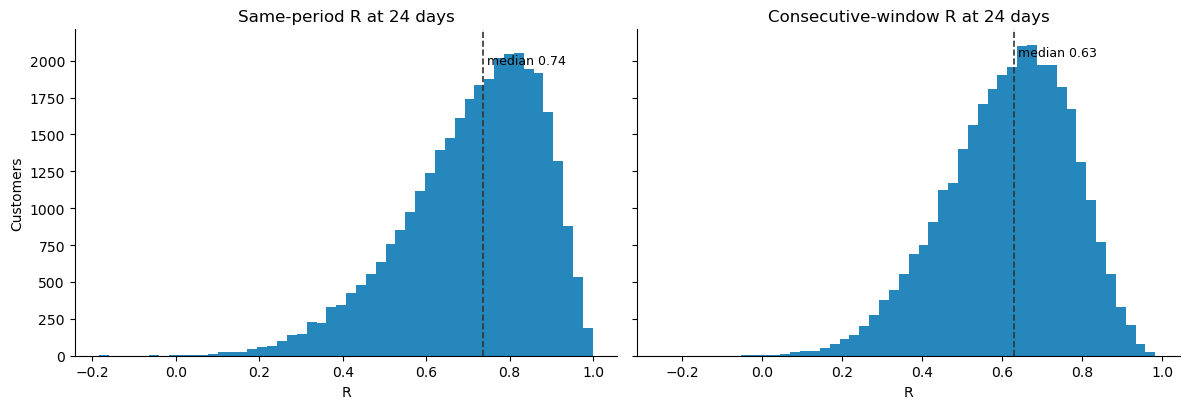

In [4]:
stability = con.sql('''
    SELECT CUSTOMER_NUMBER, peer_group, pattern_r, consecutive_r, peak_window_days
    FROM customer_stability ORDER BY CUSTOMER_NUMBER
''').pl()   # saved in notebook 45

print('Personal peak window length (share of customers):')
with pl.Config(tbl_hide_dataframe_shape=True):
    print(stability.group_by('peak_window_days').len().sort('peak_window_days')
          .with_columns((pl.col('len') / pl.col('len').sum()).round(3).alias('share')))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col, title in [(axes[0], 'pattern_r', f'Same-period R at {STABILIZATION_DAYS} days'),
                       (axes[1], 'consecutive_r', f'Consecutive-window R at {STABILIZATION_DAYS} days')]:
    ax.hist(stability[col].drop_nans().drop_nulls(), bins=50, color='#0072B2', alpha=0.85)
    med = stability[col].median()
    ax.axvline(med, color='#333333', linestyle='--', linewidth=1.2)
    ax.text(med, ax.get_ylim()[1] * 0.95, f' median {med:.2f}', fontsize=9, va='top')
    ax.set_title(title)
    ax.set_xlabel('R')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Customers')
fig.tight_layout()
fig.savefig(f'{PLOT_DIR}/stabilization_by_customer.png', dpi=150)
plt.show()

## 2. When in the year are patterns least stable?

Removing peers takes out effects that all customers share, but not differences in **timing**. For example, households switch heating or air conditioning on at different dates. The chart shows the median consecutive-window R (at the stabilization length) for each start date through the year. Dips mark periods where many customers' patterns shift relative to their peers.

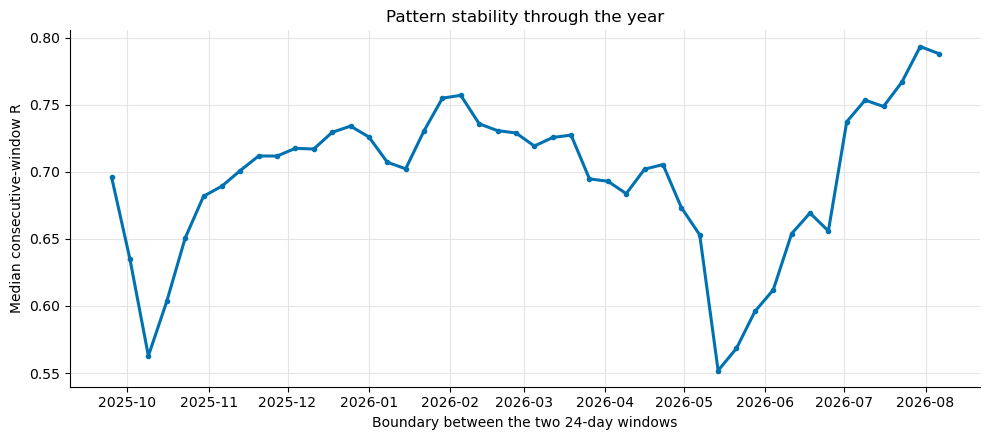

Least stable boundaries:
┌─────────────┬──────────┐
│ change_date ┆ median_r │
│ ---         ┆ ---      │
│ date        ┆ f64      │
╞═════════════╪══════════╡
│ 2026-05-14  ┆ 0.551885 │
│ 2025-10-09  ┆ 0.562795 │
│ 2026-05-21  ┆ 0.568444 │
│ 2026-05-28  ┆ 0.595907 │
│ 2025-10-16  ┆ 0.60343  │
│ 2026-06-04  ┆ 0.612    │
└─────────────┴──────────┘


In [5]:
L = STABILIZATION_DAYS
through_year = []
for a in range(0, N_DAYS - 2 * L + 1, 7):
    block = E[:, a:a + 2 * L]
    r = row_corr(np.nanmean(block[:, :L], axis=1), np.nanmean(block[:, L:], axis=1))
    through_year.append({'change_date': dates[a + L], 'median_r': float(np.nanmedian(r))})
through_year = pl.DataFrame(through_year)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(through_year['change_date'], through_year['median_r'], color='#0072B2', linewidth=2.2, marker='o', markersize=3)
ax.set_xlabel(f'Boundary between the two {L}-day windows')
ax.set_ylabel('Median consecutive-window R')
ax.set_title('Pattern stability through the year')
ax.grid(color='#e5e5e5', linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(f'{PLOT_DIR}/stability_through_year.png', dpi=150)
plt.show()

with pl.Config(tbl_rows=6, tbl_hide_dataframe_shape=True):
    print('Least stable boundaries:')
    print(through_year.sort('median_r').head(6))

Stability drops around the **seasonal transitions**: when heating comes on in autumn and when cooling starts in late spring and early summer. Households start heating and cooling on different dates and react to the first cold or hot spells differently, so their patterns shift relative to peers even though nothing has been installed.

This matters most for **heat pumps**. A customer whose use jumps relative to peers in October or November may simply have turned their heating on earlier or later than their peers. Change detection should require stronger evidence for changes that start around these transitions, or compare against peers' own heating start.

## 3. Usage level, and a cross-check with a weather model

So far we've looked at the **shape** of the daily pattern. A heat pump mainly changes **how much** is used on cold days, which shape-based R ignores. So we also measure each customer's daily **level**: average residual across all hours of the day.

To check how well weather and seasonality are removed, we compare four ways of turning daily use into a residual:

| Method | Daily residual |
|---|---|
| Raw | Normalized daily use minus the customer's own yearly average |
| Weather model | Normalized daily use minus a per-customer fit on heating degrees (below 55°F), cooling degrees (above 65°F) and weekend |
| Peer-relative | Daily average of the peer-relative residuals above |
| **Hybrid** | Peer-relative residual, then a per-customer fit on the same weather terms, which removes how the customer's weather response *differs* from their peers' |

A good method leaves **less week-to-week variation** in weekly averages (lower SD). It also leaves less **week-to-week correlation**, meaning leftover seasonal drift. The weather terms are fitted on the whole year, a limitation discussed below.

In [6]:
daily_peer = np.nanmean(E, axis=2)                                        # customers x days
daily_raw = np.nanmean(E + P[group_of], axis=2)
daily_raw = daily_raw - np.nanmean(daily_raw, axis=1, keepdims=True)

wx = con.sql('''
    SELECT w.usage_date, AVG(w.temp) AS temp, ANY_VALUE(d.day_type) AS day_type
    FROM weather_features w
    JOIN (SELECT DISTINCT usage_date, day_type FROM ami) d USING (usage_date)
    GROUP BY 1 ORDER BY 1
''').pl()
temp = wx['temp'].to_numpy()
temp = np.where(np.isnan(temp), np.nanmean(temp), temp)
W = np.column_stack([np.ones(N_DAYS), np.maximum(55 - temp, 0), np.maximum(temp - 65, 0),
                     (wx['day_type'] == 'Weekend').to_numpy().astype(float)])


def remove_weather(Y):
    """Per-customer least-squares fit of Y (customers x days) on the weather design W; return residuals."""
    mask = ~np.isnan(Y)
    XtX = np.einsum('dk,dl,cd->ckl', W, W, mask.astype(float))
    XtY = np.einsum('dk,cd->ck', W, np.where(mask, Y, 0))
    beta = np.linalg.solve(XtX + 1e-9 * np.eye(W.shape[1]), XtY[..., None])[..., 0]
    return Y - beta @ W.T


daily_weather = remove_weather(np.nanmean(E + P[group_of], axis=2))
daily_hybrid = remove_weather(daily_peer)


def weekly(A):
    n_weeks = N_DAYS // 7
    return np.nanmean(A[:, :n_weeks * 7].reshape(A.shape[0], n_weeks, 7), axis=2)


def lag1(Wk):
    a, b = Wk[:, :-1], Wk[:, 1:]
    return row_corr(a, b)


comparison = []
for name, A in [('Raw', daily_raw), ('Weather model', daily_weather),
                ('Peer-relative', daily_peer), ('Hybrid (peer + weather)', daily_hybrid)]:
    Wk = weekly(A)
    comparison.append({'method': name,
                       'median_weekly_sd': float(np.nanmedian(np.nanstd(Wk, axis=1))),
                       'median_week_to_week_corr': float(np.nanmedian(lag1(Wk)))})
comparison = pl.DataFrame(comparison).with_columns(pl.selectors.float().round(3))
comparison

method,median_weekly_sd,median_week_to_week_corr
str,f64,f64
"""Raw""",0.354,0.695
"""Weather model""",0.199,0.52
"""Peer-relative""",0.248,0.673
"""Hybrid (peer + weather)""",0.183,0.485


### What the cross-check shows

- **Every method removes a lot of variation** compared with raw use.
- **For level, peer-relative on its own is not the best.** Its weekly residuals stay strongly correlated week to week. Customers whose heating or cooling response differs from their peers' drift slowly above or below them as the seasons change, and that drift could be mistaken for adoption.
- **The hybrid (peer-relative, then a per-customer weather adjustment) leaves the least variation and the least drift.** Peers remove what all customers share (season, holidays, calendar), and the weather terms remove each customer's own extra response to temperature.

**The trade-off for change detection:** here the weather terms are fitted on the full year, so for a customer who installed a heat pump mid-winter, the fit partly absorbs the new heating response. Change detection should ideally fit the weather adjustment on a **reference period before a candidate change** and compare after against it, or compare before and after fits directly, rather than using a full-year fit.

**Conclusion:** use **peer-relative residuals for shape** (good for EV charging blocks and solar dips) and **hybrid residuals for level and temperature response** (needed for heat pumps).

### How much does level normally move?

To set a threshold for "a real change in level", we need each customer's normal variation. For window lengths from 1 to 8 weeks, we compare the average hybrid residual in one window with the next, and take the standard deviation of that difference over start dates. That is the size of a typical shift when nothing has been installed.

In [7]:
level_noise_curve = []
level_noise_by_customer = {}
for L in sorted({7, 14, 21, 28, 35, 42, 56, STABILIZATION_DAYS}):
    diffs = []
    for a in range(0, N_DAYS - 2 * L + 1, 7):
        diffs.append(np.nanmean(daily_hybrid[:, a + L:a + 2 * L], axis=1) - np.nanmean(daily_hybrid[:, a:a + L], axis=1))
    sd = np.nanstd(np.array(diffs), axis=0)
    level_noise_by_customer[L] = sd
    level_noise_curve.append({'window_days': L, 'median_level_shift_sd': float(np.nanmedian(sd)),
                              'p90_level_shift_sd': float(np.nanpercentile(sd, 90))})
level_noise_curve = pl.DataFrame(level_noise_curve).with_columns(pl.selectors.float().round(3))
level_noise_curve

window_days,median_level_shift_sd,p90_level_shift_sd
i64,f64,f64
7,0.185,0.343
14,0.164,0.326
21,0.157,0.329
24,0.154,0.33
28,0.153,0.332
35,0.148,0.33
42,0.143,0.326
56,0.132,0.314


Normal level shifts get smaller as windows get longer, quickly at first and then slowly. Going from 1 to 3 weeks removes most of the noise; going from 4 to 8 weeks helps only a little. Numbers are in units of the customer's own average use, so 0.15 means a shift of 15% of a typical hour's use. The 90th percentile is about twice the median, so some customers are much less steady than others.

For a change in level to stand out, it should be **several times** a customer's normal shift. Each customer's own figure is saved so the threshold can adapt: steady customers can be flagged on smaller changes than erratic ones.

## 4. Save the results

**`customer_stability`** (one row per customer), now complete:

| Column | Meaning |
|---|---|
| `peer_group` | Peer group (0–15) |
| `pattern_r` | Same-period R at the stabilization length: how measurable the customer's pattern is |
| `consecutive_r` | Consecutive-window R at the stabilization length: normal drift in shape |
| `peak_window_days` | Window length where the customer's own consecutive R is highest (noisy) |
| `level_shift_sd` | SD of shifts in hybrid level between consecutive windows of the stabilization length |
| `stabilization_days` | The overall stabilization length, repeated on every row for convenience |

In [8]:
stability = stability.with_columns(
    pl.Series('level_shift_sd', level_noise_by_customer[STABILIZATION_DAYS]),
    pl.lit(STABILIZATION_DAYS).alias('stabilization_days'),
)
con.register('stability_df', stability)
con.execute('CREATE OR REPLACE TABLE customer_stability AS SELECT * FROM stability_df ORDER BY CUSTOMER_NUMBER')

with pl.Config(tbl_hide_dataframe_shape=True):
    print(con.sql('SELECT COUNT(*) AS customers, MEDIAN(pattern_r) AS median_pattern_r, '
                  'MEDIAN(consecutive_r) AS median_consecutive_r, MEDIAN(level_shift_sd) AS median_level_shift_sd '
                  'FROM customer_stability').pl())

┌───────────┬──────────────────┬──────────────────────┬───────────────────────┐
│ customers ┆ median_pattern_r ┆ median_consecutive_r ┆ median_level_shift_sd │
│ ---       ┆ ---              ┆ ---                  ┆ ---                   │
│ i64       ┆ f32              ┆ f32                  ┆ f64                   │
╞═══════════╪══════════════════╪══════════════════════╪═══════════════════════╡
│ 33310     ┆ 0.73606          ┆ 0.628981             ┆ 0.15406               │
└───────────┴──────────────────┴──────────────────────┴───────────────────────┘


## Summary

- **Stripping shared effects is essential.** Raw usage patterns look similar for everyone. Relative to peers, a
  customer's pattern is specific to them.
- **Patterns take about the stabilization length (roughly 3–4 weeks) to settle**, with or without weekends included.
  Shorter windows are dominated by noise; longer ones are blurred by drift. Changes in the first and last
  stabilization length of the year can't be confirmed, because there isn't enough data on both sides.
- **Customers differ a lot** in how measurable and how steady their patterns are.
- **Use peer-relative residuals for shape and hybrid residuals for level and temperature response.**
- **Patterns shift naturally around the seasonal transitions** (autumn heating start, late-spring cooling start), which
  affects heat pumps most.

In [9]:
del E, P, daily_peer, daily_raw, daily_weather, daily_hybrid
con.close()

## Tried but not used

| Tried | Why it isn't used |
|---|---|
| **Customer-specific change thresholds** (each customer's `pattern_r`, `consecutive_r` and `level_shift_sd` were saved so a change could be judged against that customer's normal variation) | Not implemented. Notebook 45 uses one threshold for everyone: the 95th percentile of change strength among customers on no list for the technology scans, and the top 10% for the general scan. |
| **Fitting the weather adjustment on a reference period before a candidate change** | Not implemented. Notebook 45 fits each customer's weather response on the whole year, which for a mid-winter heat pump adopter partly absorbs the new heating response. |
| **Extra caution around the seasonal transitions** | Only partly: notebook 45 restricts the heat-pump scan to cold weeks, but doesn't require stronger evidence for changes that start in autumn or late spring. |
| **Hybrid level residuals** (peer-relative, then a per-customer weather fit): the best of the four methods compared in section 3 | Not carried into change detection as such: notebook 45 uses its own weather adjustments for the general and EV scans, and the peer-relative level (in cold weeks only) for the HP scan. |